In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
import json

print('Libraries imported successfully')

Libraries imported successfully


# Load Union Footprint

In [2]:
footprint_path = (
    "/home/rhoffmann/MA/Footprint/Overlap/"
    "kids_desi_full_region_union_0p025deg.npz"
)

with np.load(footprint_path, allow_pickle=False) as saved_footprint:
    footprint_ra_deg_saved = saved_footprint["ra_deg"]
    footprint_dec_deg_saved = saved_footprint["dec_deg"]
    footprint_mask_saved = saved_footprint["footprint_mask"]
    footprint_metadata_saved = json.loads(str(saved_footprint["metadata_json"]))

assert len(footprint_ra_deg_saved) == len(footprint_dec_deg_saved)
assert len(footprint_ra_deg_saved) == np.count_nonzero(footprint_mask_saved)

print(f"NPZ erfolgreich geladen und geprueft: {len(footprint_ra_deg_saved):,} RA/DEC-Paare")
print(f"Metadaten: {footprint_metadata_saved}")
print("Koordinaten stehen in footprint_ra_deg_saved und footprint_dec_deg_saved bereit.")

NPZ erfolgreich geladen und geprueft: 1,011,432 RA/DEC-Paare
Metadaten: {'description': 'KiDS AND DESI observed/full region', 'bin_size_deg': 0.025, 'n_ra_bins': 14400, 'n_dec_bins': 440, 'full_dec_min': -6.0, 'full_dec_max': 5.0, 'n_true_bins': 1011432}
Koordinaten stehen in footprint_ra_deg_saved und footprint_dec_deg_saved bereit.


# Check Footprint

In [3]:
full_bin_size = float(footprint_metadata_saved["bin_size_deg"])

n_ra_bins = int(footprint_metadata_saved["n_ra_bins"])
n_dec_bins = int(footprint_metadata_saved["n_dec_bins"])

full_dec_min = float(
    footprint_metadata_saved["full_dec_min"]
)

full_dec_max = float(
    footprint_metadata_saved["full_dec_max"]
)

print(f"full_dec_min: {full_dec_min:.6f} deg")
print(f"full_dec_max: {full_dec_max:.6f} deg")
print(f"full_bin_size: {full_bin_size:.6f} deg")
print(f"n_ra_bins: {n_ra_bins:,}")
print(f"n_dec_bins: {n_dec_bins:,}")

full_dec_min: -6.000000 deg
full_dec_max: 5.000000 deg
full_bin_size: 0.025000 deg
n_ra_bins: 14,400
n_dec_bins: 440


In [4]:
ra_centers = (
    np.arange(n_ra_bins) + 0.5
) * full_bin_size

dec_centers = (
    full_dec_min
    + (np.arange(n_dec_bins) + 0.5) * full_bin_size
)

print(
    f"RA-Zentren: {ra_centers.min():.6f} "
    f"bis {ra_centers.max():.6f} deg"
)

print(
    f"DEC-Zentren: {dec_centers.min():.6f} "
    f"bis {dec_centers.max():.6f} deg"
)

RA-Zentren: 0.012500 bis 359.987500 deg
DEC-Zentren: -5.987500 bis 4.987500 deg


In [5]:
# Gespeicherte True-Bins rekonstruieren
true_ra_indices, true_dec_indices = np.where(
    footprint_mask_saved
)

ra_centers_from_mask = ra_centers[true_ra_indices]
dec_centers_from_mask = dec_centers[true_dec_indices]

assert np.allclose(
    ra_centers_from_mask,
    footprint_ra_deg_saved,
)

assert np.allclose(
    dec_centers_from_mask,
    footprint_dec_deg_saved,
)

print("RA/DEC-Zentren stimmen mit der gespeicherten Maske ueberein.")

RA/DEC-Zentren stimmen mit der gespeicherten Maske ueberein.


In [6]:
def filter_catalog_by_footprint(
    df,
    ra_column,
    dec_column,
    footprint_mask,
    full_bin_size,
    full_dec_min,
):
    ra = np.asarray(df[ra_column], dtype=np.float64)
    dec = np.asarray(df[dec_column], dtype=np.float64)

    valid = np.isfinite(ra) & np.isfinite(dec)

    # RA in [0, 360)
    ra_valid = np.mod(ra, 360.0)

    # Genau wie beim Erzeugen des Footprints
    ra_indices = np.floor(
        ra_valid / full_bin_size
    ).astype(np.int64)

    dec_indices = np.floor(
        (dec - full_dec_min) / full_bin_size
    ).astype(np.int64)

    n_ra_bins, n_dec_bins = footprint_mask.shape

    valid &= (
        (ra_indices >= 0)
        & (ra_indices < n_ra_bins)
        & (dec_indices >= 0)
        & (dec_indices < n_dec_bins)
    )

    footprint_selected = np.zeros(len(df), dtype=bool)

    footprint_selected[valid] = footprint_mask[
        ra_indices[valid],
        dec_indices[valid]
    ]

    # Wichtig: iloc
    return df.iloc[np.flatnonzero(footprint_selected)].copy()

# Load KiDS Data

In [7]:
kids_fits_file = "/DATA02/rhoffmann/KiDs/KiDS_Legacy_NS_unblind_final.fits.gz"
fits_files = [kids_fits_file]
kids_hdul = fits.open(kids_fits_file)
kids_data = kids_hdul[1].data
print(f'Loaded KiDS data from {kids_fits_file}')
print('Shape:', kids_data.shape)

Loaded KiDS data from /DATA02/rhoffmann/KiDs/KiDS_Legacy_NS_unblind_final.fits.gz
Shape: (40894394,)


# Filter KiDS Data

In [8]:
kids_rows_before_filter = len(kids_data)
kids_data = kids_data[kids_data['DECJ2000'] >= -15]
kids_df = pd.DataFrame(kids_data)

print(f'KiDS rows removed with DEC < -15 deg: {kids_rows_before_filter - len(kids_data):,}')
print(f'KiDS rows remaining: {len(kids_data):,}')
print(f'KiDS DataFrame shape: {kids_df.shape}')

KiDS rows removed with DEC < -15 deg: 20,423,231
KiDS rows remaining: 20,471,163
KiDS DataFrame shape: (20471163, 50)


In [9]:
kids_df_footprint = filter_catalog_by_footprint(
    kids_df,
    ra_column="RAJ2000",
    dec_column="DECJ2000",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print(
    f"KiDS objects in footprint: "
    f"{len(kids_df_footprint):,}"
)

print(
    f"KiDS objects removed by footprint: "
    f"{len(kids_df) - len(kids_df_footprint):,}"
)

KiDS objects in footprint: 20,188,547
KiDS objects removed by footprint: 282,616


In [10]:
kids_df = pd.DataFrame(kids_data[:10])
display(kids_df.head(10))
print(kids_df_footprint["Z_B"].head(20).to_list())

,THELI_NAME,RAJ2000,DECJ2000,PATCH,Level,FLUX_RADIUS,Agaper,Bgaper,SG2DPHOT,MAG_AUTO,...,PSF_e2_exp3,PSF_e1_exp4,PSF_e2_exp4,PSF_e1_exp5,PSF_e2_exp5,shear_weight_only,gold_weight_only,e1,e2,weight
0,KIDS_206p6_m3p5,206.125977,-3.961563,N_patch,1.606028e-08,2.194760,1.04,1.02,0,24.430859,...,0.0114,0.0298,-0.0174,99.0000,99.0000,0.095622,0.9,-0.219127,-0.290608,0.086060
1,KIDS_166p5_m3p5,166.787131,-3.961561,N_patch,1.419212e-08,2.289083,0.76,0.73,0,24.337156,...,99.0000,99.0000,99.0000,0.0003,0.0056,5.592556,1.0,-0.452054,0.107626,5.592556
2,KIDS_213p6_m3p5,213.529059,-3.961560,N_patch,1.621344e-08,2.139463,0.77,0.73,0,24.212248,...,-0.0162,-0.0050,-0.0054,0.0038,-0.0158,9.224947,1.0,-0.485352,0.061764,9.224947
3,KIDS_185p5_m3p5,185.395896,-3.961554,N_patch,1.648447e-08,2.844821,1.02,1.01,0,24.479443,...,99.0000,0.0261,0.0018,99.0000,99.0000,2.268958,1.0,-0.381656,-0.633715,2.268958
4,KIDS_202p6_m3p5,202.708561,-3.961551,N_patch,1.675953e-08,6.320547,1.13,1.13,0,21.123289,...,99.0000,0.0333,0.0072,-0.0003,-0.0033,15.453700,1.0,0.063528,0.019502,15.453700
5,KIDS_192p5_m3p5,192.664470,-3.961547,N_patch,1.595112e-08,2.181150,0.81,0.76,0,22.556332,...,-0.0119,0.0290,0.0013,0.0109,0.0041,13.755224,1.0,0.634960,-0.116970,13.755224
6,KIDS_209p6_m3p5,209.503696,-3.961545,N_patch,1.635181e-08,2.856561,0.77,0.72,0,24.069933,...,99.0000,-0.0178,-0.0075,0.0074,-0.0346,2.570638,0.8,0.539179,-0.000728,2.056511
7,KIDS_211p6_m3p5,211.243906,-3.961545,N_patch,1.631785e-08,2.249372,0.75,0.71,0,24.491802,...,0.0100,0.0146,-0.0009,99.0000,99.0000,0.638309,0.8,0.191577,0.554511,0.510647
8,KIDS_199p6_m3p5,199.106318,-3.961544,N_patch,1.567321e-08,2.631182,0.81,0.73,0,23.879148,...,0.0131,99.0000,99.0000,0.0175,-0.0012,11.302017,1.0,0.394700,-0.565559,11.302017
9,KIDS_196p5_m3p5,196.376354,-3.961543,N_patch,1.456847e-08,2.901005,1.03,1.01,0,24.251553,...,99.0000,0.0218,-0.0180,0.0344,-0.0046,3.100717,1.0,0.295218,-0.209102,3.100717


[1.2, 0.53, 1.53, 0.8, 0.71, 0.33, 1.36, 0.9, 0.39, 0.65, 0.81, 0.78, 0.79, 0.65, 1.07, 0.54, 1.05, 0.46, 0.96, 0.25]


# Load DESI Data

In [11]:
# =========================
# BGS ANY
# =========================

with fits.open('/DATA02/rhoffmann/DESI/BGS ANY/BGS ANY.fits') as hdul:
    bgs_data = hdul[1].data

    bgs_dict = {}

    for name in bgs_data.names:
        column = bgs_data[name]

        # Big-Endian -> native Byte-Reihenfolge
        if column.dtype.byteorder == '>':
            column = column.byteswap().view(
                column.dtype.newbyteorder('=')
            )

        # Native NumPy-Kopie
        bgs_dict[name] = np.array(column)

    bgs_any_df = pd.DataFrame(bgs_dict)

print("BGS ANY:", bgs_any_df.shape)


# =========================
# LRG
# =========================

with fits.open('/DATA02/rhoffmann/DESI/LRG/LRG.fits') as hdul:
    lrg_data = hdul[1].data

    lrg_dict = {}

    for name in lrg_data.names:
        column = lrg_data[name]

        # Big-Endian -> native Byte-Reihenfolge
        if column.dtype.byteorder == '>':
            column = column.byteswap().view(
                column.dtype.newbyteorder('=')
            )

        # Native NumPy-Kopie
        lrg_dict[name] = np.array(column)

    lrg_df = pd.DataFrame(lrg_dict)

print("LRG:", lrg_df.shape)

BGS ANY: (1027650, 18)
LRG: (515770, 13)


In [12]:
print("\nBig-Endian-Spalten in BGS:")
for column in bgs_any_df.columns:
    dtype = bgs_any_df[column].to_numpy().dtype
    if dtype.byteorder == '>':
        print(column, dtype)

print("\nBig-Endian-Spalten in LRG:")
for column in lrg_df.columns:
    dtype = lrg_df[column].to_numpy().dtype
    if dtype.byteorder == '>':
        print(column, dtype)


Big-Endian-Spalten in BGS:

Big-Endian-Spalten in LRG:


# Filter DESI Data

In [13]:
bgs_any_footprint_df = filter_catalog_by_footprint(
    bgs_any_df,
    ra_column="desi_dr1_lss_v1_5_bgs_any_dat.ra",
    dec_column="desi_dr1_lss_v1_5_bgs_any_dat.dec",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print("BGS vorher:", len(bgs_any_df))
print("BGS nach Footprint:", len(bgs_any_footprint_df))


BGS vorher: 1027650
BGS nach Footprint: 577879


In [14]:
lrg_footprint_df = filter_catalog_by_footprint(
    lrg_df,
    ra_column="desi_dr1_lss_v1_5_lrg_dat.ra",
    dec_column="desi_dr1_lss_v1_5_lrg_dat.dec",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print("LRG vorher:", len(lrg_df))
print("LRG nach Footprint:", len(lrg_footprint_df))

LRG vorher: 515770
LRG nach Footprint: 288692


In [15]:
display(bgs_any_df.head(10))
display(lrg_df.head(10))

,desi_dr1_lss_v1_5_bgs_any_dat.targetid,desi_dr1_lss_v1_5_bgs_any_dat.z,desi_dr1_lss_v1_5_bgs_any_dat.ntile,desi_dr1_lss_v1_5_bgs_any_dat.ra,desi_dr1_lss_v1_5_bgs_any_dat.dec,desi_dr1_lss_v1_5_bgs_any_dat.photsys,desi_dr1_lss_v1_5_bgs_any_dat.frac_tlobs_tiles,desi_dr1_lss_v1_5_bgs_any_dat.weight_zfail,desi_dr1_lss_v1_5_bgs_any_dat.weight,desi_dr1_lss_v1_5_bgs_any_dat.weight_comp,desi_dr1_lss_v1_5_bgs_any_dat.weight_sys,desi_dr1_lss_v1_5_bgs_any_dat.flux_g_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_r_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_z_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_w1_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_w2_dered,desi_dr1_lss_v1_5_bgs_any_dat.nx,desi_dr1_lss_v1_5_bgs_any_dat.weight_fkp
0,39627642084789536,0.302015,1,127.404466,-5.986855,S,0.985703,1.000000,0.419068,1.0,1.0,6.116484,25.559881,53.221317,69.084984,46.982098,0.002449,0.055123
1,39627642084789952,0.359715,1,127.418185,-5.975900,S,0.985703,1.001585,0.839464,2.0,1.0,2.635645,10.894744,21.935942,27.790562,19.837645,0.001441,0.090206
2,39627642088981286,0.082816,1,127.556968,-5.937155,S,0.985703,1.001294,0.419611,1.0,1.0,19.786264,33.849583,51.113781,41.900726,26.596487,0.023028,0.006165
3,39627642088981352,0.353340,1,127.559128,-5.990249,S,0.985703,1.003566,2.102812,5.0,1.0,3.190038,14.313684,33.791916,56.791729,38.210106,0.001441,0.090206
4,39627642088982139,0.356098,1,127.587646,-5.971131,S,0.985703,1.000000,0.838136,2.0,1.0,8.712421,33.903305,71.832222,104.307724,71.601875,0.001441,0.090206
5,39627642088984585,0.032162,1,127.681697,-5.937755,S,0.985703,1.002479,0.840214,2.0,1.0,42.189106,60.564434,70.121040,-10.677300,-17.857647,0.051039,0.002791
6,39627642088984813,0.175009,1,127.691605,-5.986173,S,0.985703,1.000000,0.838136,2.0,1.0,10.380540,19.050573,29.618589,25.051371,16.632957,0.008768,0.016032
7,39627642088985356,0.191770,1,127.713399,-5.933927,S,0.985703,1.000000,0.419068,1.0,1.0,21.949341,41.463440,65.220070,65.187569,51.757973,0.007611,0.018424
8,39627642088986177,0.163207,1,127.743969,-5.897843,S,0.985703,1.002536,0.420131,1.0,1.0,13.812540,26.652590,42.469215,38.996716,24.205725,0.009573,0.014703
9,39627642088986840,0.163253,1,127.771028,-5.918813,S,0.985703,1.000000,0.838136,2.0,1.0,6.961936,18.219381,32.975201,25.242237,16.024746,0.009573,0.014703


,desi_dr1_lss_v1_5_lrg_dat.targetid,desi_dr1_lss_v1_5_lrg_dat.z,desi_dr1_lss_v1_5_lrg_dat.ntile,desi_dr1_lss_v1_5_lrg_dat.ra,desi_dr1_lss_v1_5_lrg_dat.dec,desi_dr1_lss_v1_5_lrg_dat.photsys,desi_dr1_lss_v1_5_lrg_dat.frac_tlobs_tiles,desi_dr1_lss_v1_5_lrg_dat.weight_zfail,desi_dr1_lss_v1_5_lrg_dat.weight_sys,desi_dr1_lss_v1_5_lrg_dat.weight,desi_dr1_lss_v1_5_lrg_dat.weight_comp,desi_dr1_lss_v1_5_lrg_dat.nx,desi_dr1_lss_v1_5_lrg_dat.weight_fkp
0,39627642084787603,0.809332,1,127.331994,-5.913763,S,0.888268,1.009297,0.995586,0.611313,1.0,0.000299,0.250469
1,39627642084789818,0.693160,1,127.413705,-5.907806,S,0.888268,1.001131,0.981486,1.195559,2.0,0.000267,0.272466
2,39627642093176735,0.432908,2,127.863737,-5.957493,S,0.937931,1.000000,0.972920,1.469349,2.0,0.000374,0.210814
3,39627642093178130,0.942167,2,127.926200,-5.891132,S,0.937931,1.002733,0.998015,0.755684,1.0,0.000212,0.320591
4,39627642097369566,0.515453,2,128.048670,-5.947349,S,0.937931,1.000000,0.983710,0.742822,1.0,0.000363,0.216011
5,39627642097370424,0.767572,2,128.078599,-5.976601,S,0.937931,1.000000,0.993249,2.250075,3.0,0.000384,0.206578
6,39627642097370758,0.433292,2,128.091401,-5.948706,S,0.937931,1.000000,0.983710,1.485644,2.0,0.000374,0.210814
7,39627642097372183,0.567776,2,128.147980,-5.972916,S,0.937931,1.000000,0.983710,0.742822,1.0,0.000391,0.203588
8,39627642101566397,0.829045,2,128.396630,-5.983671,S,0.937931,1.005718,0.993142,0.754232,1.0,0.000385,0.206258
9,39627642105758960,0.952197,2,128.584453,-5.998511,S,0.937931,1.006176,0.993142,0.754576,1.0,0.000199,0.334309


# Display Data

In [16]:
ra_bins = np.linspace(-180, 180, 3601)
dec_bins = np.linspace(-90, 90, 1801)
counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

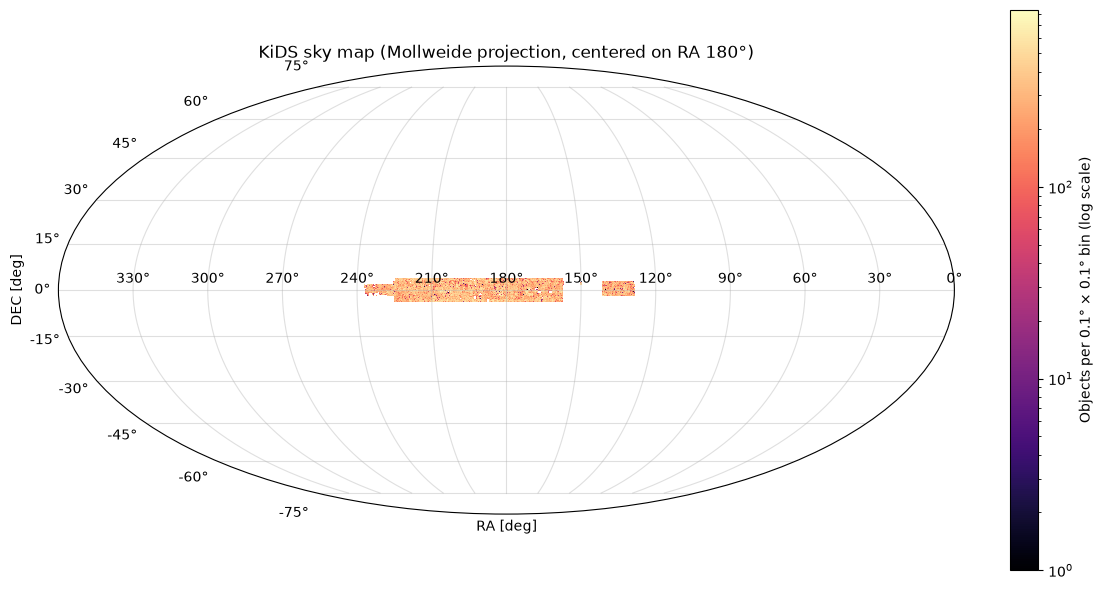

In [17]:
from matplotlib.colors import LogNorm

ra_bins = np.linspace(-180, 180, 3601)
dec_bins = np.linspace(-90, 90, 1801)
counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

for start in range(0, len(kids_df_footprint), 1_000_000):
    chunk = kids_df_footprint[start:start + 1_000_000]
    ra_longitude = -((chunk['RAJ2000'] % 360) - 180)
    counts += np.histogram2d(
        ra_longitude,
        chunk['DECJ2000'],
        bins=(ra_bins, dec_bins),
    )[0].astype(np.int64)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
image = ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_less_equal(counts.T, 0),
    norm=LogNorm(vmin=1),
    cmap='magma',
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('KiDS sky map (Mollweide projection, centered on RA 180°)')
fig.colorbar(image, ax=ax, label='Objects per 0.1° × 0.1° bin (log scale)')
plt.tight_layout()
plt.show()

In [ ]:
desi_counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

for catalog in (bgs_any_footprint_df, lrg_footprint_df):
    ra_column = next(column for column in catalog.columns if column.lower().endswith('.ra'))
    dec_column = next(column for column in catalog.columns if column.lower().endswith('.dec'))
    ra_longitude = -((catalog[ra_column].to_numpy() % 360) - 180)
    desi_counts += np.histogram2d(
        ra_longitude,
        catalog[dec_column].to_numpy(),
        bins=(ra_bins, dec_bins),
    )[0].astype(np.int64)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
image = ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_less_equal(desi_counts.T, 0),
    norm=LogNorm(vmin=1),
    cmap='magma',
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('DESI sky map (BGS ANY + LRG, Mollweide projection)')
fig.colorbar(image, ax=ax, label='Objects per 0.1° × 0.1° bin (log scale)')
plt.tight_layout()
plt.show()

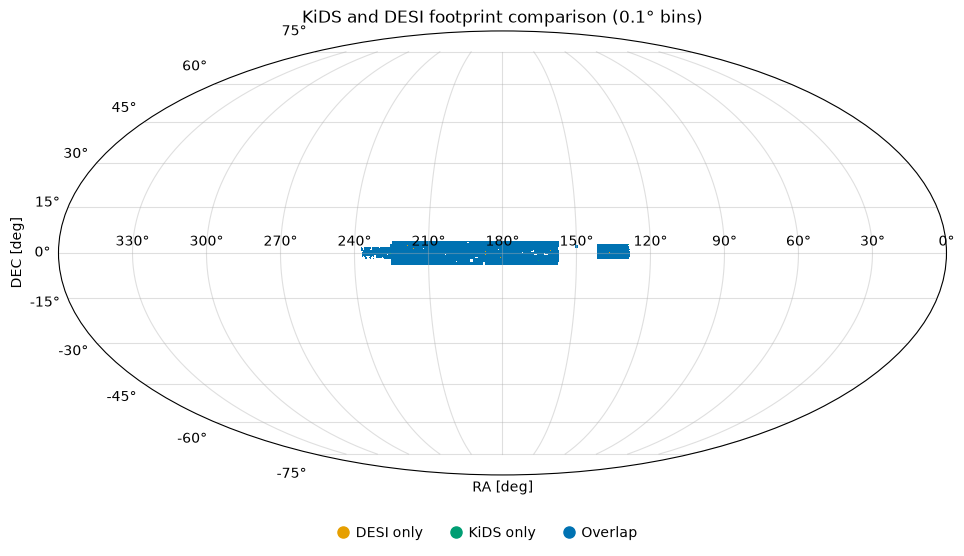

KiDS fully covered by DESI: No
Overlapping bins: 64,462
KiDS-only bins: 91
DESI-only bins: 69


In [ ]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

kids_occupied = counts > 0
desi_occupied = desi_counts > 0
shared = kids_occupied & desi_occupied
kids_only = kids_occupied & ~desi_occupied
desi_only = desi_occupied & ~kids_occupied

comparison = np.zeros_like(counts, dtype=np.uint8)
comparison[desi_only] = 1
comparison[kids_only] = 2
comparison[shared] = 3

comparison_cmap = ListedColormap(['#e69f00', '#009e73', '#0072b2'])
comparison_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], comparison_cmap.N)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_equal(comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('KiDS and DESI footprint comparison (0.1° bins)')

legend_items = [
    Line2D([], [], marker='o', linestyle='None', color='#e69f00', markersize=8,
           label='DESI only'),
    Line2D([], [], marker='o', linestyle='None', color='#009e73', markersize=8,
           label='KiDS only'),
    Line2D([], [], marker='o', linestyle='None', color='#0072b2', markersize=8,
           label='Overlap'),
]
fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.14)
plt.show()

print(f'KiDS fully covered by DESI: {"Yes" if not np.any(kids_only) else "No"}')
print(f'Overlapping bins: {np.count_nonzero(shared):,}')
print(f'KiDS-only bins: {np.count_nonzero(kids_only):,}')
print(f'DESI-only bins: {np.count_nonzero(desi_only):,}')

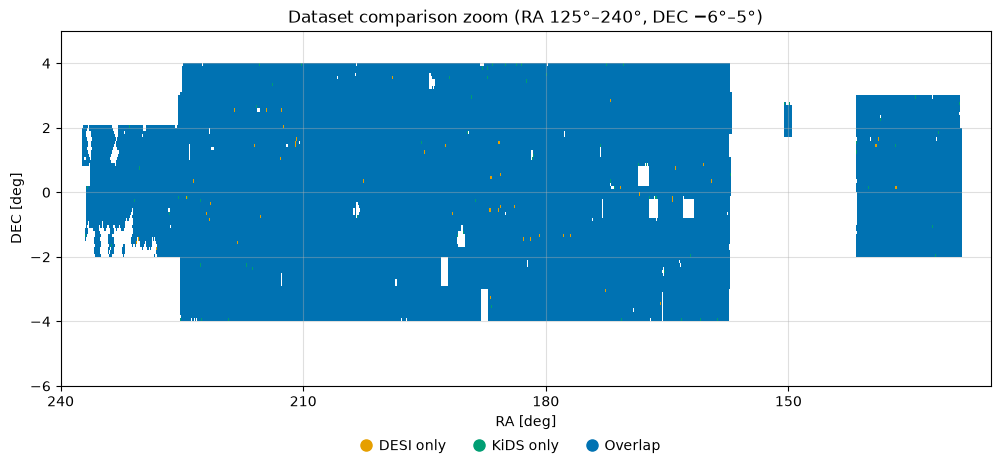

Non-empty bins in zoom: 64,622


In [ ]:
ra_longitude_centers = (ra_bins[:-1] + ra_bins[1:]) / 2
ra_centers = (180 - ra_longitude_centers) % 360
dec_centers = (dec_bins[:-1] + dec_bins[1:]) / 2

ra_indices = np.flatnonzero((ra_centers >= 120) & (ra_centers <= 240))
dec_indices = np.flatnonzero((dec_centers >= -10) & (dec_centers <= 10))

zoom_ra_edges = 180 - ra_bins[ra_indices[0]:ra_indices[-1] + 2]
zoom_dec_edges = dec_bins[dec_indices[0]:dec_indices[-1] + 2]
zoom_comparison = comparison[np.ix_(ra_indices, dec_indices)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(
    zoom_ra_edges,
    zoom_dec_edges,
    np.ma.masked_equal(zoom_comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ax.set_xlim(240, 125)
ax.set_ylim(-6, 5)
ax.set_xticks(np.arange(240, 124, -30))
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('Dataset comparison zoom (RA 125°–240°, DEC −6°–5°)')
fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.17)
plt.show()
print(f'Non-empty bins in zoom: {np.count_nonzero(zoom_comparison):,}')

# Tomobins KiDS

In [ ]:
# KiDS tomographic source bins
kids_tomo_bins = {}

for tomo_bin in sorted(kids_df_footprint["TOMOBIN"].dropna().unique()):

    kids_tomo_bins[int(tomo_bin)] = kids_df_footprint[
        kids_df_footprint["TOMOBIN"] == tomo_bin
    ].copy()

    print(
        f"KiDS TOMOBIN {int(tomo_bin)}: "
        f"{len(kids_tomo_bins[int(tomo_bin)])} sources"
    )

KiDS TOMOBIN 1: 3683163 sources
KiDS TOMOBIN 2: 3779080 sources
KiDS TOMOBIN 3: 3449734 sources
KiDS TOMOBIN 4: 3367244 sources
KiDS TOMOBIN 5: 3105132 sources
KiDS TOMOBIN 6: 2804194 sources


In [ ]:
print(
    kids_df_footprint
    .groupby("TOMOBIN")["Z_B"]
    .agg(["count", "min", "max", "median", "mean"])
)

           count   min   max  median      mean
TOMOBIN                                       
1        3683163  0.11  0.42    0.31  0.297212
2        3779080  0.43  0.58    0.51  0.507719
3        3449734  0.59  0.71    0.64  0.646761
4        3367244  0.72  0.90    0.81  0.807634
5        3105132  0.91  1.14    1.01  1.014071
6        2804194  1.15  2.00    1.34  1.384357


In [ ]:
print([
    col for col in bgs_any_footprint_df.columns
    if "z" in col.lower() or "redshift" in col.lower()
])

print([
    col for col in lrg_footprint_df.columns
    if "z" in col.lower() or "redshift" in col.lower()
])

['desi_dr1_lss_v1_5_bgs_any_dat.z', 'desi_dr1_lss_v1_5_bgs_any_dat.weight_zfail', 'desi_dr1_lss_v1_5_bgs_any_dat.flux_z_dered']
['desi_dr1_lss_v1_5_lrg_dat.z', 'desi_dr1_lss_v1_5_lrg_dat.weight_zfail']


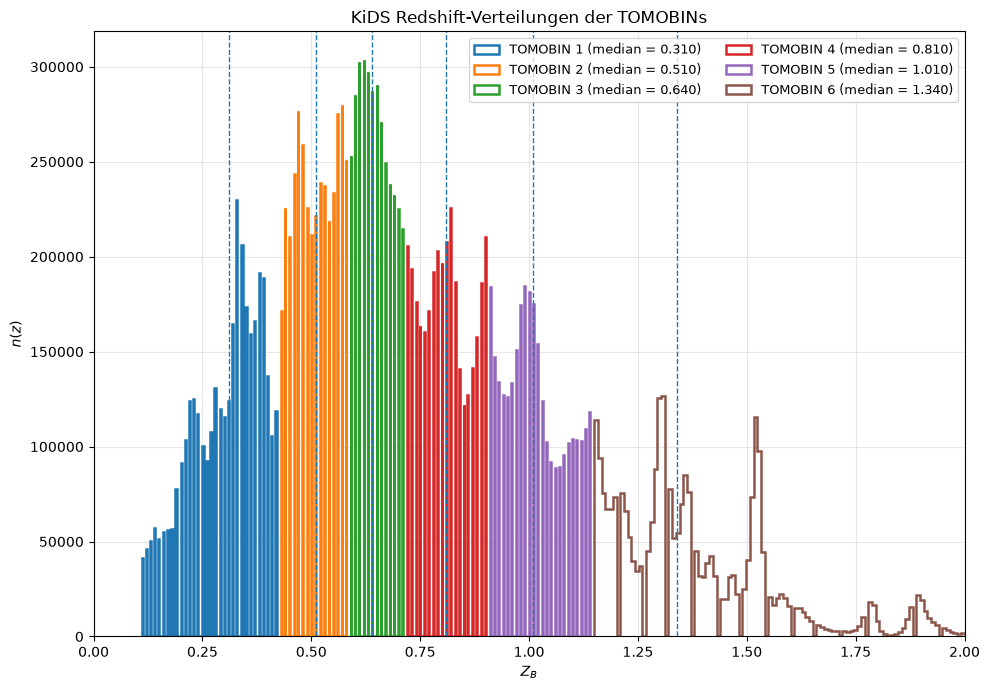

In [ ]:
# ============================================================
# KiDS Redshift-Verteilungen der TOMOBINs
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 7))


for tomo_bin in sorted(
    kids_df_footprint["TOMOBIN"].dropna().unique()
):

    # --------------------------------------------------------
    # Quellen dieses TOMOBINs auswählen
    # --------------------------------------------------------

    tomo_df = kids_df_footprint[
        kids_df_footprint["TOMOBIN"] == tomo_bin
    ]


    # --------------------------------------------------------
    # Gültige Z_B-Werte
    # --------------------------------------------------------

    z = tomo_df["Z_B"].to_numpy(
        dtype=np.float64
    )

    z = z[np.isfinite(z)]


    if len(z) == 0:
        continue


    # --------------------------------------------------------
    # Redshift-Verteilung
    # --------------------------------------------------------

    plt.hist(
        z,
        bins=100,
        density=False,
        histtype="step",
        linewidth=1.8,
        label=(
            f"TOMOBIN {int(tomo_bin)} "
            f"(median = {np.median(z):.3f})"
        ),
    )


    # --------------------------------------------------------
    # Median markieren
    # --------------------------------------------------------

    plt.axvline(
        np.median(z),
        linestyle="--",
        linewidth=1,
    )


# ============================================================
# Plot-Einstellungen
# ============================================================

plt.xlabel(
    r"$Z_B$"
)

plt.ylabel(
    r"$n(z)$"
)

plt.title(
    "KiDS Redshift-Verteilungen der TOMOBINs"
)

plt.xlim(
    0,
    2.0
)

plt.grid(
    True,
    which="both",
    linestyle="-",
    alpha=0.3,
)

plt.legend(
    fontsize=9,
    ncol=2,
)

plt.tight_layout()

plt.show()

# Tomobins DESI

In [ ]:
# ============================================================
# DESI BGS tomographic lens bins
# ============================================================

BGS_Z_COLUMN = "desi_dr1_lss_v1_5_bgs_any_dat.z"

bgs_z_bins = {
    "BGS 0.1-0.2": (0.1, 0.2),
    "BGS 0.2-0.3": (0.2, 0.3),
    "BGS 0.3-0.4": (0.3, 0.4),
}

bgs_tomo_bins = {}

for tomo_name, (z_min, z_max) in bgs_z_bins.items():

    mask = (
        np.isfinite(bgs_any_footprint_df[BGS_Z_COLUMN])
        & (bgs_any_footprint_df[BGS_Z_COLUMN] >= z_min)
        & (bgs_any_footprint_df[BGS_Z_COLUMN] < z_max)
    )

    bgs_tomo_bins[tomo_name] = (
        bgs_any_footprint_df.loc[mask].copy()
    )

    print(
        f"{tomo_name}: "
        f"{len(bgs_tomo_bins[tomo_name])} lenses"
    )

BGS 0.1-0.2: 165717 lenses
BGS 0.2-0.3: 183190 lenses
BGS 0.3-0.4: 115895 lenses


In [ ]:
# ============================================================
# DESI LRG tomographic lens bins
# ============================================================

LRG_Z_COLUMN = "desi_dr1_lss_v1_5_lrg_dat.z"

lrg_z_bins = {
    "LRG 0.4-0.6": (0.4, 0.6),
    "LRG 0.6-0.8": (0.6, 0.8),
}

lrg_tomo_bins = {}

for tomo_name, (z_min, z_max) in lrg_z_bins.items():

    mask = (
        np.isfinite(lrg_footprint_df[LRG_Z_COLUMN])
        & (lrg_footprint_df[LRG_Z_COLUMN] >= z_min)
        & (lrg_footprint_df[LRG_Z_COLUMN] < z_max)
    )

    lrg_tomo_bins[tomo_name] = (
        lrg_footprint_df.loc[mask].copy()
    )

    print(
        f"{tomo_name}: "
        f"{len(lrg_tomo_bins[tomo_name])} lenses"
    )

LRG 0.4-0.6: 67741 lenses
LRG 0.6-0.8: 104687 lenses


In [ ]:
print("\nBGS tomographic bins:")
for name, df in bgs_tomo_bins.items():

    print(
        f"{name:15s} "
        f"N = {len(df):8d}, "
        f"median z = {df[BGS_Z_COLUMN].median():.3f}, "
        f"mean z = {df[BGS_Z_COLUMN].mean():.3f}"
    )


print("\nLRG tomographic bins:")
for name, df in lrg_tomo_bins.items():

    print(
        f"{name:15s} "
        f"N = {len(df):8d}, "
        f"median z = {df[LRG_Z_COLUMN].median():.3f}, "
        f"mean z = {df[LRG_Z_COLUMN].mean():.3f}"
    )


BGS tomographic bins:
BGS 0.1-0.2     N =   165717, median z = 0.152, mean z = 0.152
BGS 0.2-0.3     N =   183190, median z = 0.250, mean z = 0.249
BGS 0.3-0.4     N =   115895, median z = 0.343, mean z = 0.345

LRG tomographic bins:
LRG 0.4-0.6     N =    67741, median z = 0.516, mean z = 0.510
LRG 0.6-0.8     N =   104687, median z = 0.711, mean z = 0.707


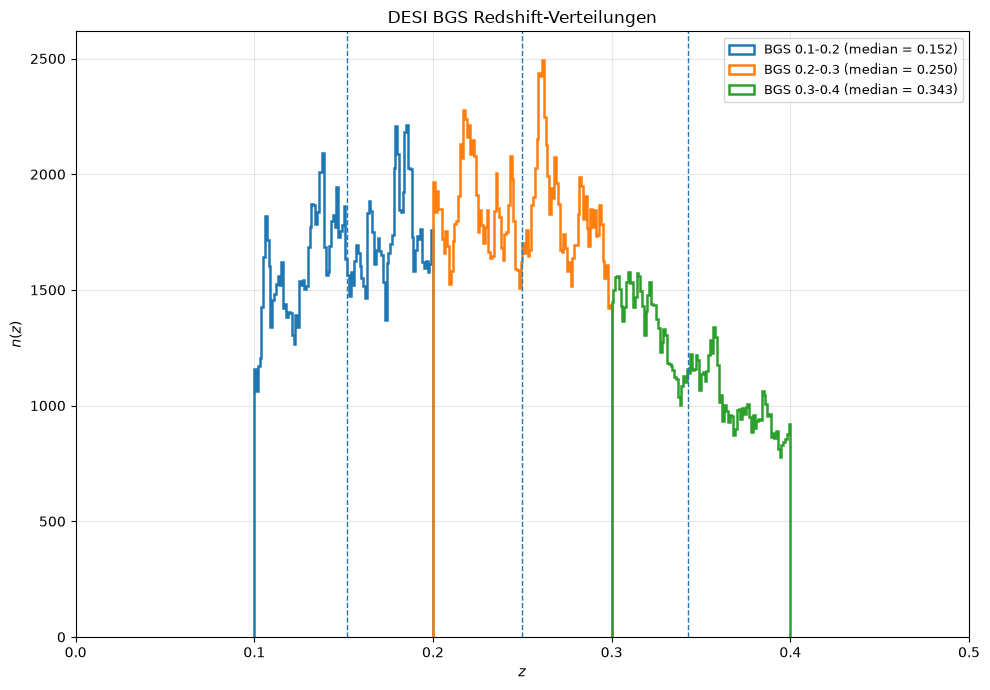

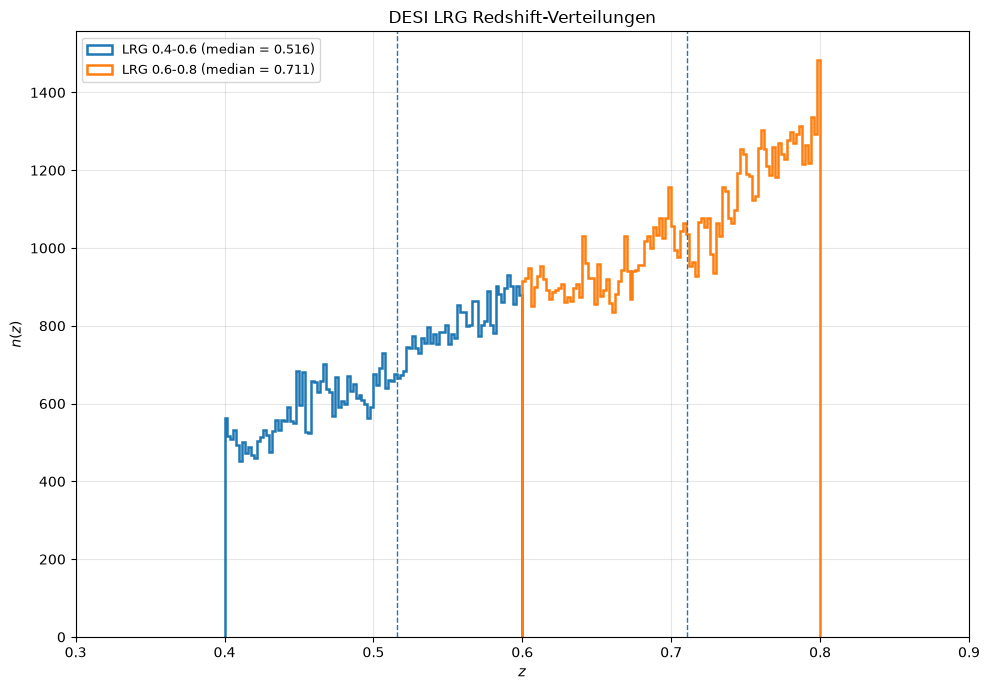

In [ ]:
# ============================================================
# DESI BGS + LRG Redshift-Verteilungen
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. BGS Redshift-Verteilungen
# ============================================================

plt.figure(figsize=(10, 7))

for tomo_name in bgs_tomo_bins:

    tomo_df = bgs_tomo_bins[tomo_name]

    # --------------------------------------------------------
    # Gültige Redshifts
    # --------------------------------------------------------

    z = tomo_df[BGS_Z_COLUMN].to_numpy(
        dtype=np.float64
    )

    z = z[np.isfinite(z)]

    if len(z) == 0:
        continue

    # --------------------------------------------------------
    # Histogramm
    # --------------------------------------------------------

    plt.hist(
        z,
        bins=100,
        density=False,
        histtype="step",
        linewidth=1.8,
        label=(
            f"{tomo_name} "
            f"(median = {np.median(z):.3f})"
        ),
    )

    # --------------------------------------------------------
    # Median markieren
    # --------------------------------------------------------

    plt.axvline(
        np.median(z),
        linestyle="--",
        linewidth=1,
    )


# ============================================================
# Plot-Einstellungen
# ============================================================

plt.xlabel(
    r"$z$"
)

plt.ylabel(
    r"$n(z)$"
)

plt.title(
    "DESI BGS Redshift-Verteilungen"
)

plt.xlim(
    0.0,
    0.5
)

plt.grid(
    True,
    linestyle="-",
    alpha=0.3,
)

plt.legend(
    fontsize=9,
)

plt.tight_layout()

plt.show()


# ============================================================
# 2. LRG Redshift-Verteilungen
# ============================================================

plt.figure(figsize=(10, 7))

for tomo_name in lrg_tomo_bins:

    tomo_df = lrg_tomo_bins[tomo_name]

    # --------------------------------------------------------
    # Gültige Redshifts
    # --------------------------------------------------------

    z = tomo_df[LRG_Z_COLUMN].to_numpy(
        dtype=np.float64
    )

    z = z[np.isfinite(z)]

    if len(z) == 0:
        continue

    # --------------------------------------------------------
    # Histogramm
    # --------------------------------------------------------

    plt.hist(
        z,
        bins=100,
        density=False,
        histtype="step",
        linewidth=1.8,
        label=(
            f"{tomo_name} "
            f"(median = {np.median(z):.3f})"
        ),
    )

    # --------------------------------------------------------
    # Median markieren
    # --------------------------------------------------------

    plt.axvline(
        np.median(z),
        linestyle="--",
        linewidth=1,
    )


# ============================================================
# Plot-Einstellungen
# ============================================================

plt.xlabel(
    r"$z$"
)

plt.ylabel(
    r"$n(z)$"
)

plt.title(
    "DESI LRG Redshift-Verteilungen"
)

plt.xlim(
    0.3,
    0.9
)

plt.grid(
    True,
    linestyle="-",
    alpha=0.3,
)

plt.legend(
    fontsize=9,
)

plt.tight_layout()

plt.show()

# G2L Lensing Profiles with TreeCorr

Erstelle KiDS Source-Kataloge
KiDS TOMOBIN 1: 3,683,163 Quellen (Z_B ~ 0.11-0.42)
KiDS TOMOBIN 2: 3,779,080 Quellen (Z_B ~ 0.43-0.58)
KiDS TOMOBIN 3: 3,449,734 Quellen (Z_B ~ 0.59-0.71)
KiDS TOMOBIN 4: 3,367,244 Quellen (Z_B ~ 0.72-0.90)
KiDS TOMOBIN 5: 3,105,132 Quellen (Z_B ~ 0.91-1.14)
KiDS TOMOBIN 6: 2,804,194 Quellen (Z_B ~ 1.15-2.00)


Erstelle DESI BGS Lens-Kataloge
BGS 0.1-0.2: 165,717 Lenses (z = 0.1-0.2)
BGS 0.2-0.3: 183,190 Lenses (z = 0.2-0.3)
BGS 0.3-0.4: 115,895 Lenses (z = 0.3-0.4)


Erstelle DESI LRG Lens-Kataloge
LRG 0.4-0.6: 67,741 Lenses (z = 0.4-0.6)
LRG 0.6-0.8: 104,687 Lenses (z = 0.6-0.8)


Median-Redshifts der KiDS Source-TOMOBINs
KiDS TOMOBIN 1: median z = 0.3100
KiDS TOMOBIN 2: median z = 0.5100
KiDS TOMOBIN 3: median z = 0.6400
KiDS TOMOBIN 4: median z = 0.8100
KiDS TOMOBIN 5: median z = 1.0100
KiDS TOMOBIN 6: median z = 1.3400


Median-Redshifts der DESI BGS Lens-TOMOBINs
BGS 0.1-0.2: median z = 0.1520
BGS 0.2-0.3: median z = 0.2498
BGS 0.3-0.4: median z = 0

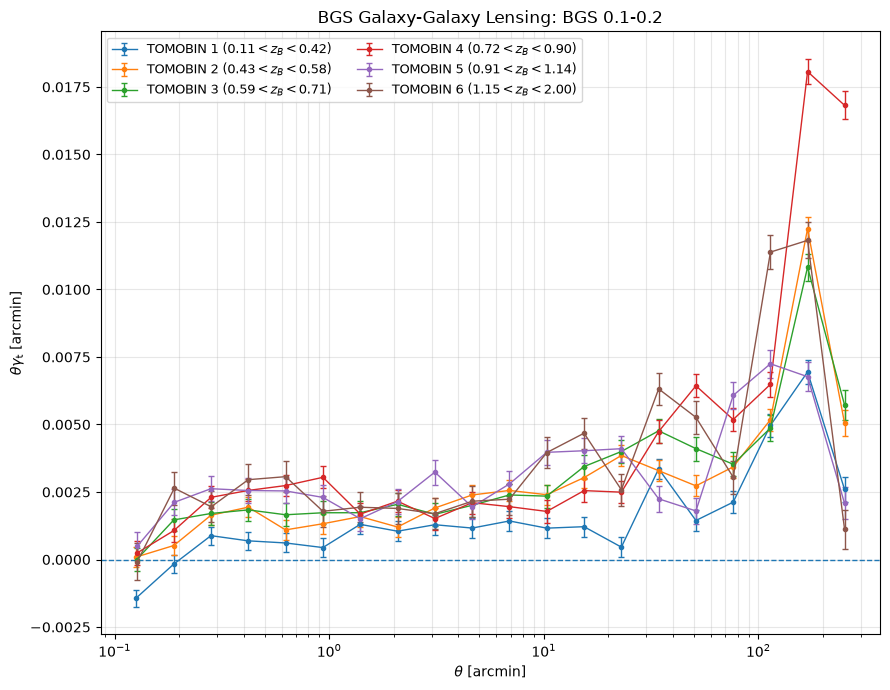

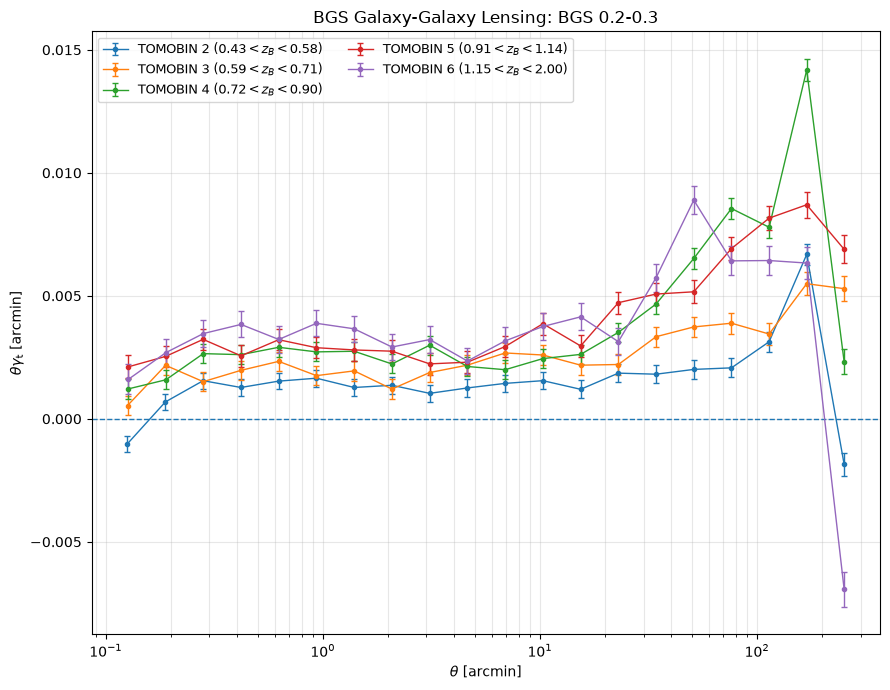

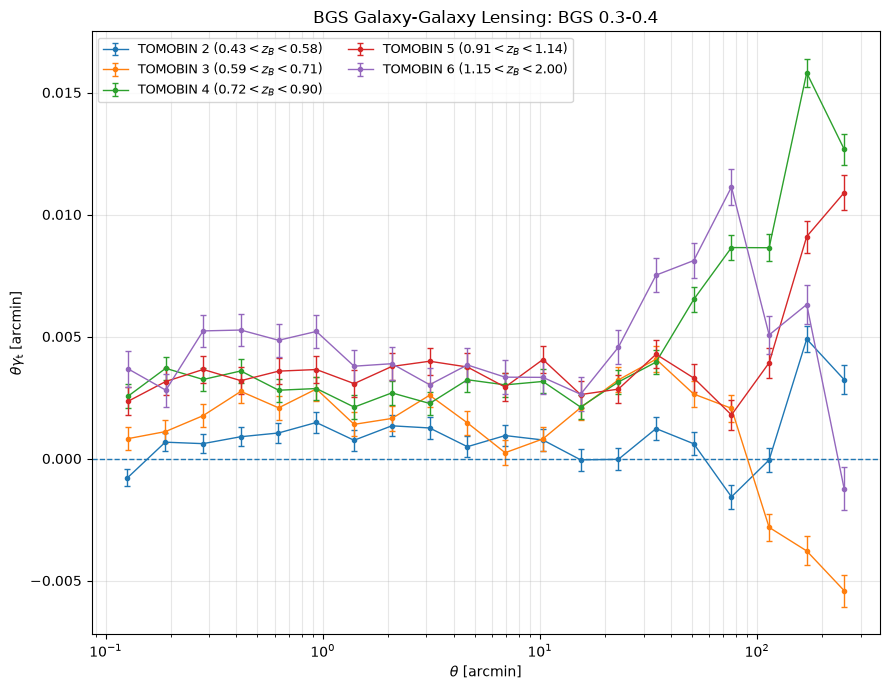

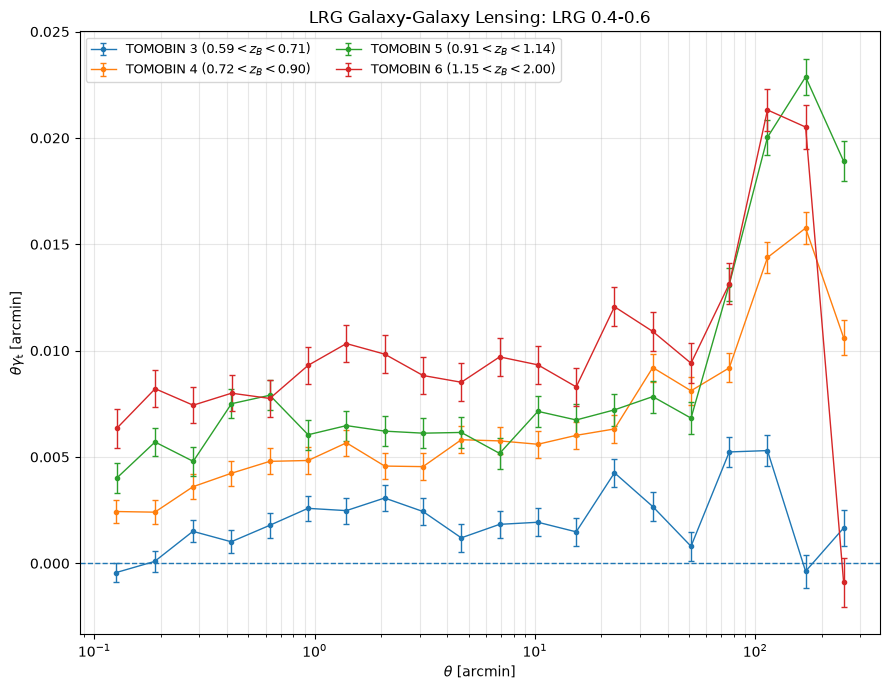

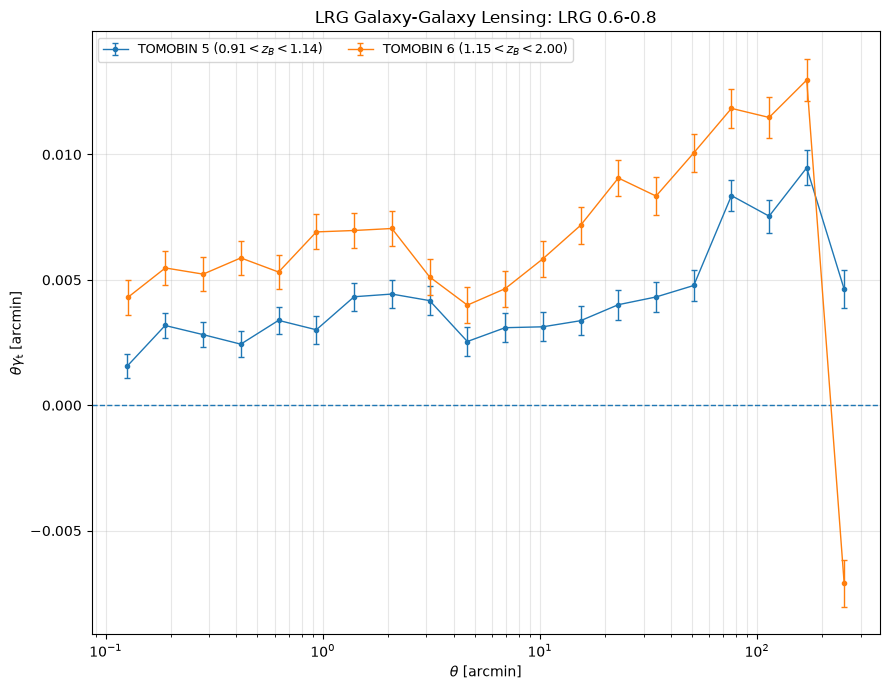

In [ ]:
import numpy as np
import treecorr
import matplotlib.pyplot as plt


# ============================================================
# TreeCorr-Konfiguration
# ============================================================

config = {
    "nbins": 20,
    "min_sep": 0.1,
    "max_sep": 300.0,
    "sep_units": "arcmin",
}


# ============================================================
# Definition der Tomographie
# ============================================================


# ------------------------------------------------------------
# KiDS Source TOMOBINs
# ------------------------------------------------------------

kids_tomo_bins = {
    1: (0.11, 0.42),
    2: (0.43, 0.58),
    3: (0.59, 0.71),
    4: (0.72, 0.90),
    5: (0.91, 1.14),
    6: (1.15, 2.00),
}


# ------------------------------------------------------------
# DESI BGS Lens TOMOBINs
# ------------------------------------------------------------

bgs_z_column = "desi_dr1_lss_v1_5_bgs_any_dat.z"

bgs_z_bins = {
    "BGS 0.1-0.2": (0.1, 0.2),
    "BGS 0.2-0.3": (0.2, 0.3),
    "BGS 0.3-0.4": (0.3, 0.4),
}


# ------------------------------------------------------------
# DESI LRG Lens TOMOBINs
# ------------------------------------------------------------

lrg_z_column = "desi_dr1_lss_v1_5_lrg_dat.z"

lrg_z_bins = {
    "LRG 0.4-0.6": (0.4, 0.6),
    "LRG 0.6-0.8": (0.6, 0.8),
}


# ============================================================
# PAPER-KRITERIUM
#
# Eine Source-TOMOBIN wird nur dann hinter einem Lens-TOMOBIN
# akzeptiert, wenn gilt:
#
#     median(z_source) > median(z_lens) + 0.1
#
# Die Prozentzahl der tatsächlichen Quellen hinter dem Lens
# wird zusätzlich ausgegeben, ist aber NICHT der Filter.
# ============================================================

redshift_separation = 0.1


# ============================================================
# 1. KiDS Source-Kataloge für alle TOMOBINs
# ============================================================

print("=" * 75)
print("Erstelle KiDS Source-Kataloge")
print("=" * 75)


kids_source_cats = {}
kids_tomo_dfs = {}


for tomo_bin, (z_min, z_max) in kids_tomo_bins.items():

    mask = (
        kids_df_footprint["TOMOBIN"] == tomo_bin
    )

    tomo_df = kids_df_footprint.loc[
        mask
    ].copy()

    kids_tomo_dfs[tomo_bin] = tomo_df

    kids_source_cats[tomo_bin] = treecorr.Catalog(
        ra=tomo_df[
            "RAJ2000"
        ].to_numpy(dtype=np.float64),

        dec=tomo_df[
            "DECJ2000"
        ].to_numpy(dtype=np.float64),

        ra_units="deg",
        dec_units="deg",

        g1=tomo_df[
            "e1"
        ].to_numpy(dtype=np.float64),

        g2=tomo_df[
            "e2"
        ].to_numpy(dtype=np.float64),

        w=tomo_df[
            "weight"
        ].to_numpy(dtype=np.float64),
    )

    print(
        f"KiDS TOMOBIN {tomo_bin}: "
        f"{len(tomo_df):,} Quellen "
        f"(Z_B ~ {z_min:.2f}-{z_max:.2f})"
    )


# ============================================================
# 2. DESI BGS Lens-Kataloge
# ============================================================

print("\n")
print("=" * 75)
print("Erstelle DESI BGS Lens-Kataloge")
print("=" * 75)


bgs_tomo_dfs = {}
bgs_lens_cats = {}


for tomo_name, (z_min, z_max) in bgs_z_bins.items():

    mask = (
        np.isfinite(
            bgs_any_footprint_df[
                bgs_z_column
            ]
        )

        & (
            bgs_any_footprint_df[
                bgs_z_column
            ]
            >= z_min
        )

        & (
            bgs_any_footprint_df[
                bgs_z_column
            ]
            < z_max
        )
    )

    tomo_df = bgs_any_footprint_df.loc[
        mask
    ].copy()

    bgs_tomo_dfs[tomo_name] = tomo_df

    bgs_lens_cats[tomo_name] = treecorr.Catalog(

        ra=tomo_df[
            "desi_dr1_lss_v1_5_bgs_any_dat.ra"
        ].to_numpy(dtype=np.float64),

        dec=tomo_df[
            "desi_dr1_lss_v1_5_bgs_any_dat.dec"
        ].to_numpy(dtype=np.float64),

        ra_units="deg",
        dec_units="deg",
    )

    print(
        f"{tomo_name}: "
        f"{len(tomo_df):,} Lenses "
        f"(z = {z_min:.1f}-{z_max:.1f})"
    )


# ============================================================
# 3. DESI LRG Lens-Kataloge
# ============================================================

print("\n")
print("=" * 75)
print("Erstelle DESI LRG Lens-Kataloge")
print("=" * 75)


lrg_tomo_dfs = {}
lrg_lens_cats = {}


for tomo_name, (z_min, z_max) in lrg_z_bins.items():

    mask = (
        np.isfinite(
            lrg_footprint_df[
                lrg_z_column
            ]
        )

        & (
            lrg_footprint_df[
                lrg_z_column
            ]
            >= z_min
        )

        & (
            lrg_footprint_df[
                lrg_z_column
            ]
            < z_max
        )
    )

    tomo_df = lrg_footprint_df.loc[
        mask
    ].copy()

    lrg_tomo_dfs[tomo_name] = tomo_df

    lrg_lens_cats[tomo_name] = treecorr.Catalog(

        ra=tomo_df[
            "desi_dr1_lss_v1_5_lrg_dat.ra"
        ].to_numpy(dtype=np.float64),

        dec=tomo_df[
            "desi_dr1_lss_v1_5_lrg_dat.dec"
        ].to_numpy(dtype=np.float64),

        ra_units="deg",
        dec_units="deg",
    )

    print(
        f"{tomo_name}: "
        f"{len(tomo_df):,} Lenses "
        f"(z = {z_min:.1f}-{z_max:.1f})"
    )


# ============================================================
# 4. Median-Redshifts der KiDS Source-TOMOBINs
# ============================================================

print("\n")
print("=" * 75)
print("Median-Redshifts der KiDS Source-TOMOBINs")
print("=" * 75)


source_z_column = "Z_B"

kids_source_z_median = {}


for source_bin, df in kids_tomo_dfs.items():

    z_source = df[
        source_z_column
    ].to_numpy(dtype=np.float64)

    z_source = z_source[
        np.isfinite(z_source)
    ]

    if len(z_source) == 0:

        z_median = np.nan

    else:

        z_median = np.median(
            z_source
        )

    kids_source_z_median[
        source_bin
    ] = z_median

    print(
        f"KiDS TOMOBIN {source_bin}: "
        f"median z = {z_median:.4f}"
    )


# ============================================================
# 5. Median-Redshifts der DESI BGS Lens-TOMOBINs
# ============================================================

print("\n")
print("=" * 75)
print("Median-Redshifts der DESI BGS Lens-TOMOBINs")
print("=" * 75)


bgs_lens_z_median = {}


for bgs_name, df in bgs_tomo_dfs.items():

    z_lens = df[
        bgs_z_column
    ].to_numpy(dtype=np.float64)

    z_lens = z_lens[
        np.isfinite(z_lens)
    ]

    if len(z_lens) == 0:

        z_median = np.nan

    else:

        z_median = np.median(
            z_lens
        )

    bgs_lens_z_median[
        bgs_name
    ] = z_median

    print(
        f"{bgs_name}: "
        f"median z = {z_median:.4f}"
    )


# ============================================================
# 6. Median-Redshifts der DESI LRG Lens-TOMOBINs
# ============================================================

print("\n")
print("=" * 75)
print("Median-Redshifts der DESI LRG Lens-TOMOBINs")
print("=" * 75)


lrg_lens_z_median = {}


for lrg_name, df in lrg_tomo_dfs.items():

    z_lens = df[
        lrg_z_column
    ].to_numpy(dtype=np.float64)

    z_lens = z_lens[
        np.isfinite(z_lens)
    ]

    if len(z_lens) == 0:

        z_median = np.nan

    else:

        z_median = np.median(
            z_lens
        )

    lrg_lens_z_median[
        lrg_name
    ] = z_median

    print(
        f"{lrg_name}: "
        f"median z = {z_median:.4f}"
    )


# ============================================================
# 7. Anteil der tatsächlichen KiDS-Quellen hinter dem Lens
#
#    Diese Prozentzahl wird NUR als Information ausgegeben.
#
#    Sie ist NICHT das Filterkriterium.
#
#    Berechnung:
#
#    f_behind =
#
#        N(Z_B > z_lens,median)
#        -----------------------
#        N(gültige Z_B)
# ============================================================

def source_fraction_behind(
    source_df,
    z_source_column,
    z_lens,
):

    z_source = source_df[
        z_source_column
    ].to_numpy(dtype=np.float64)

    valid = np.isfinite(
        z_source
    )

    z_source = z_source[
        valid
    ]

    if len(z_source) == 0:

        return np.nan

    fraction = np.mean(
        z_source > z_lens
    )

    return fraction


# ============================================================
# 8. BGS Source/Lens-Filter
#
#    PAPER:
#
#    median(z_source) > median(z_lens) + 0.1
# ============================================================

print("\n")
print("=" * 75)
print("BGS Source/Lens-TOMOBIN Filter")
print("=" * 75)


allowed_bgs_combinations = {}

bgs_source_behind_fraction = {}


for bgs_name, z_lens_median in (
    bgs_lens_z_median.items()
):

    allowed_bgs_combinations[
        bgs_name
    ] = []

    bgs_source_behind_fraction[
        bgs_name
    ] = {}

    print("\n")
    print(
        f"{bgs_name}"
    )

    print(
        f"  Lens median z = "
        f"{z_lens_median:.4f}"
    )

    print(
        f"  Paper-Kriterium: "
        f"z_source > "
        f"{z_lens_median + redshift_separation:.4f}"
    )

    for source_bin in sorted(
        kids_tomo_dfs
    ):

        z_source_median = (
            kids_source_z_median[
                source_bin
            ]
        )

        # ----------------------------------------------------
        # Tatsächlicher Anteil der Quellen hinter dem Lens
        # ----------------------------------------------------

        fraction = source_fraction_behind(
            kids_tomo_dfs[
                source_bin
            ],
            source_z_column,
            z_lens_median,
        )

        bgs_source_behind_fraction[
            bgs_name
        ][source_bin] = fraction

        # ----------------------------------------------------
        # PAPER FILTER
        # ----------------------------------------------------

        allowed = (
            np.isfinite(
                z_source_median
            )

            and np.isfinite(
                z_lens_median
            )

            and (
                z_source_median
                >
                z_lens_median
                + redshift_separation
            )
        )

        if allowed:

            status = "ERLAUBT"

            allowed_bgs_combinations[
                bgs_name
            ].append(
                source_bin
            )

        else:

            status = "GEFILTERT"

        print(
            f"    KiDS TOMOBIN {source_bin}: "
            f"median z_s = {z_source_median:.4f}, "
            f"{fraction * 100:.1f}% "
            f"hinter Lens "
            f"--> {status}"
        )


# ============================================================
# 9. LRG Source/Lens-Filter
#
#    PAPER:
#
#    median(z_source) > median(z_lens) + 0.1
# ============================================================

print("\n")
print("=" * 75)
print("LRG Source/Lens-TOMOBIN Filter")
print("=" * 75)


allowed_lrg_combinations = {}

lrg_source_behind_fraction = {}


for lrg_name, z_lens_median in (
    lrg_lens_z_median.items()
):

    allowed_lrg_combinations[
        lrg_name
    ] = []

    lrg_source_behind_fraction[
        lrg_name
    ] = {}

    print("\n")
    print(
        f"{lrg_name}"
    )

    print(
        f"  Lens median z = "
        f"{z_lens_median:.4f}"
    )

    print(
        f"  Paper-Kriterium: "
        f"z_source > "
        f"{z_lens_median + redshift_separation:.4f}"
    )

    for source_bin in sorted(
        kids_tomo_dfs
    ):

        z_source_median = (
            kids_source_z_median[
                source_bin
            ]
        )

        # ----------------------------------------------------
        # Tatsächlicher Anteil der Quellen hinter dem Lens
        # ----------------------------------------------------

        fraction = source_fraction_behind(
            kids_tomo_dfs[
                source_bin
            ],
            source_z_column,
            z_lens_median,
        )

        lrg_source_behind_fraction[
            lrg_name
        ][source_bin] = fraction

        # ----------------------------------------------------
        # PAPER FILTER
        # ----------------------------------------------------

        allowed = (
            np.isfinite(
                z_source_median
            )

            and np.isfinite(
                z_lens_median
            )

            and (
                z_source_median
                >
                z_lens_median
                + redshift_separation
            )
        )

        if allowed:

            status = "ERLAUBT"

            allowed_lrg_combinations[
                lrg_name
            ].append(
                source_bin
            )

        else:

            status = "GEFILTERT"

        print(
            f"    KiDS TOMOBIN {source_bin}: "
            f"median z_s = {z_source_median:.4f}, "
            f"{fraction * 100:.1f}% "
            f"hinter Lens "
            f"--> {status}"
        )


# ============================================================
# 10. Zusammenfassung der erlaubten Kombinationen
# ============================================================

print("\n")
print("=" * 75)
print("ERLAUBTE GGL-KOMBINATIONEN")
print("=" * 75)


print(
    "\nVerwendetes Paper-Kriterium:"
)

print(
    "    median(z_source) > median(z_lens) + 0.1"
)


print("\nBGS:")

for bgs_name, source_bins in (
    allowed_bgs_combinations.items()
):

    print(
        f"  {bgs_name}: "
        f"KiDS TOMOBINs {source_bins}"
    )


print("\nLRG:")

for lrg_name, source_bins in (
    allowed_lrg_combinations.items()
):

    print(
        f"  {lrg_name}: "
        f"KiDS TOMOBINs {source_bins}"
    )


# ============================================================
# 11. Funktion zur Berechnung eines GGL-Profils
# ============================================================

def calculate_ggl_profile(
    lens_cat,
    source_cat,
    config,
):

    """
    Berechnet ein Galaxy-Galaxy-Lensing-Profil
    mit TreeCorr.
    """

    ng = treecorr.NGCorrelation(
        config
    )

    ng.process(
        lens_cat,
        source_cat
    )

    r = ng.meanr

    gammat = ng.xi

    gammax = ng.xi_im

    sigma = np.sqrt(
        ng.varxi
    )

    return (
        r,
        gammat,
        gammax,
        sigma,
        ng,
    )


# ============================================================
# 12. GGL-Ergebnisse
# ============================================================

ggl_results = {}


# ============================================================
# 13. BGS × KiDS
#
#     NUR Source-TOMOBINs, die das Paper-Kriterium erfüllen
# ============================================================

print("\n")
print("=" * 75)
print("Berechne BGS × KiDS tomographisches GGL")
print("=" * 75)


for bgs_name, bgs_lens_cat in (
    bgs_lens_cats.items()
):

    print(
        f"\n{bgs_name}"
    )

    allowed_source_bins = (
        allowed_bgs_combinations[
            bgs_name
        ]
    )

    for source_bin in (
        allowed_source_bins
    ):

        source_cat = (
            kids_source_cats[
                source_bin
            ]
        )

        print(
            f"    {bgs_name} × "
            f"KiDS TOMOBIN {source_bin}"
        )

        result = calculate_ggl_profile(
            bgs_lens_cat,
            source_cat,
            config,
        )

        ggl_results[
            (
                bgs_name,
                source_bin,
            )
        ] = result


# ============================================================
# 14. LRG × KiDS
#
#     NUR Source-TOMOBINs, die das Paper-Kriterium erfüllen
# ============================================================

print("\n")
print("=" * 75)
print("Berechne LRG × KiDS tomographisches GGL")
print("=" * 75)


for lrg_name, lrg_lens_cat in (
    lrg_lens_cats.items()
):

    print(
        f"\n{lrg_name}"
    )

    allowed_source_bins = (
        allowed_lrg_combinations[
            lrg_name
        ]
    )

    for source_bin in (
        allowed_source_bins
    ):

        source_cat = (
            kids_source_cats[
                source_bin
            ]
        )

        print(
            f"    {lrg_name} × "
            f"KiDS TOMOBIN {source_bin}"
        )

        result = calculate_ggl_profile(
            lrg_lens_cat,
            source_cat,
            config,
        )

        ggl_results[
            (
                lrg_name,
                source_bin,
            )
        ] = result


# ============================================================
# 15. Zusammenfassung der Kataloggrößen
# ============================================================

print("\n")
print("=" * 75)
print("Tomographische Kataloggrößen")
print("=" * 75)


print("\nKiDS Source TOMOBINs:")


for tomo_bin, df in (
    kids_tomo_dfs.items()
):

    z_median = df[
        source_z_column
    ].median()

    print(
        f"  TOMOBIN {tomo_bin}: "
        f"{len(df):,} sources, "
        f"median z = {z_median:.3f}"
    )


print("\nDESI BGS Lens TOMOBINs:")


for tomo_name, df in (
    bgs_tomo_dfs.items()
):

    z_median = df[
        bgs_z_column
    ].median()

    print(
        f"  {tomo_name}: "
        f"{len(df):,} lenses, "
        f"median z = {z_median:.3f}"
    )


print("\nDESI LRG Lens TOMOBINs:")


for tomo_name, df in (
    lrg_tomo_dfs.items()
):

    z_median = df[
        lrg_z_column
    ].median()

    print(
        f"  {tomo_name}: "
        f"{len(df):,} lenses, "
        f"median z = {z_median:.3f}"
    )


# ============================================================
# 16. Source-TOMOBIN Labels für Plots
# ============================================================

source_bin_labels = {

    1: r"TOMOBIN 1 ($0.11 < z_B < 0.42$)",

    2: r"TOMOBIN 2 ($0.43 < z_B < 0.58$)",

    3: r"TOMOBIN 3 ($0.59 < z_B < 0.71$)",

    4: r"TOMOBIN 4 ($0.72 < z_B < 0.90$)",

    5: r"TOMOBIN 5 ($0.91 < z_B < 1.14$)",

    6: r"TOMOBIN 6 ($1.15 < z_B < 2.00$)",
}


# ============================================================
# 17. Plot: BGS tomographisch
#
#     NUR erlaubte Source-TOMOBINs
#
#     y = theta * gamma_t
#
#     KEINE 10^3-SKALIERUNG
# ============================================================

for bgs_name in bgs_lens_cats:

    plt.figure(
        figsize=(9, 7)
    )

    for source_bin in (
        allowed_bgs_combinations[
            bgs_name
        ]
    ):

        r, gammat, gammax, sigma, ng = (
            ggl_results[
                (
                    bgs_name,
                    source_bin,
                )
            ]
        )

        # ----------------------------------------------------
        # Keine Multiplikation mit 1000
        # ----------------------------------------------------

        theta_gamma_t = (
            r * gammat
        )

        theta_gamma_t_error = (
            r * sigma
        )

        plt.errorbar(
            r,
            theta_gamma_t,
            yerr=theta_gamma_t_error,
            marker="o",
            markersize=3,
            linestyle="-",
            linewidth=1,
            capsize=2,
            label=source_bin_labels[
                source_bin
            ],
        )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    plt.xscale(
        "log"
    )

    plt.xlabel(
        r"$\theta$ [arcmin]"
    )

    plt.ylabel(
        r"$\theta\gamma_{\rm t}$ [arcmin]"
    )

    plt.title(
        f"BGS Galaxy-Galaxy Lensing: "
        f"{bgs_name}"
    )

    plt.legend(
        fontsize=9,
        ncol=2,
    )

    plt.grid(
        True,
        which="both",
        linestyle="-",
        alpha=0.3,
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 18. Plot: LRG tomographisch
#
#     NUR erlaubte Source-TOMOBINs
#
#     y = theta * gamma_t
#
#     KEINE 10^3-SKALIERUNG
# ============================================================

for lrg_name in lrg_lens_cats:

    plt.figure(
        figsize=(9, 7)
    )

    for source_bin in (
        allowed_lrg_combinations[
            lrg_name
        ]
    ):

        r, gammat, gammax, sigma, ng = (
            ggl_results[
                (
                    lrg_name,
                    source_bin,
                )
            ]
        )

        # ----------------------------------------------------
        # Keine Multiplikation mit 1000
        # ----------------------------------------------------

        theta_gamma_t = (
            r * gammat
        )

        theta_gamma_t_error = (
            r * sigma
        )

        plt.errorbar(
            r,
            theta_gamma_t,
            yerr=theta_gamma_t_error,
            marker="o",
            markersize=3,
            linestyle="-",
            linewidth=1,
            capsize=2,
            label=source_bin_labels[
                source_bin
            ],
        )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    plt.xscale(
        "log"
    )

    plt.xlabel(
        r"$\theta$ [arcmin]"
    )

    plt.ylabel(
        r"$\theta\gamma_{\rm t}$ [arcmin]"
    )

    plt.title(
        f"LRG Galaxy-Galaxy Lensing: "
        f"{lrg_name}"
    )

    plt.legend(
        fontsize=9,
        ncol=2,
    )

    plt.grid(
        True,
        which="both",
        linestyle="-",
        alpha=0.3,
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 19. FITS-Speicherung
#
#     VORERST DEAKTIVIERT
# ============================================================

# print("\n")
# print("=" * 75)
# print("Speichere TreeCorr-Ergebnisse")
# print("=" * 75)


# try:

#     for lens_name, source_bin in ggl_results:

#         ng = ggl_results[
#             (
#                 lens_name,
#                 source_bin,
#             )
#         ][4]

#         filename = (
#             "ggl_"
#             + lens_name.replace(
#                 " ",
#                 "_"
#             )
#             .replace(
#                 "-",
#                 "_"
#             )
#             + f"_KiDS_TOMOBIN{source_bin}.fits"
#         )

#         ng.write(
#             filename,
#             file_type="FITS",
#         )

#         print(
#             f"Gespeichert: {filename}"
#         )


#     print(
#         "\nAlle TreeCorr-Ergebnisse gespeichert."
#     )


# except ModuleNotFoundError as e:

#     print(
#         "\nFITS-Speicherung nicht möglich."
#     )

#     print(
#         "Es fehlt vermutlich das Python-Paket 'fitsio'."
#     )